## Categorical Variables

### Relevant Information
Links:
[Tutorial](https://www.kaggle.com/code/alexisbcook/categorical-variables/tutorial)
[, Exercise](https://www.kaggle.com/code/marcopolo1313/exercise-categorical-variables/edit?fromFork=1)

Note: 
1. OHE won't be suitable for variables having more than 15 unique values. A.K.A Cardinality
2. Ordinal Encoding works good for tree-based models and when a proper ranking could be defined. Like Worst(0) < Good(1) < Best(2)

![Screenshot 2026-11-25 104120.jpg](<attachment:Screenshot 2026-11-25 104120.jpg>)
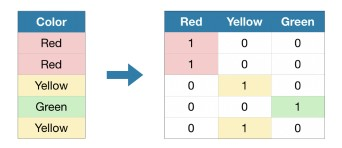

### SETUP

#### Load Data and Filtering out High Cardinality Data

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.read_csv(r'C:\Users\Anwesh\Desktop\Py\MachineLearning\KaggleML-Intermediate\DatasetsKaggleML-Intermediate\melb_data.csv')
y = data.Price
X = data.drop(['Price'], axis=1)

X_train_full, X_valid_full, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=122)
list_of_missing_columns = [cols for cols in X_train_full.columns if X_train_full[cols].isnull().any()]
X_train_full.drop(list_of_missing_columns,axis=1) # inplace = True by default
X_valid_full.drop(list_of_missing_columns, axis=1)

#Remove High Cardinality Data
low_cardinality_cols = [cols for cols in X_train_full.columns if X_train_full[cols].nunique()<10 and X_train_full[cols].dtype=='string']
#Select non-object, numerical Data
numerical_cols = [cols for cols in X_train_full.columns if X_train_full[cols].dtype in ['float64', 'int64']]

eligible_columns = low_cardinality_cols + numerical_cols
X_train = X_train_full[eligible_columns].copy()
X_valid = X_valid_full[eligible_columns].copy()


#### Peek

In [8]:
data.head(1)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0


In [9]:
X_train.head()

,Type,Method,Regionname,Rooms,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
11376,u,S,Northern Metropolitan,2,16.1,3088.0,2.0,1.0,1.0,168.0,NaN,1985.0,-37.70801,145.10689,8524.0
8682,u,PI,Southern Metropolitan,2,4.6,3142.0,2.0,2.0,2.0,586.0,119.0,1990.0,-37.84270,145.02360,7217.0
7893,t,S,Southern Metropolitan,3,9.2,3146.0,3.0,2.0,2.0,184.0,NaN,NaN,-37.86440,145.06300,10412.0
13441,h,S,Northern Metropolitan,3,16.1,3088.0,3.0,2.0,2.0,873.0,NaN,1985.0,-37.69324,145.10230,8524.0
989,h,S,Eastern Metropolitan,4,13.1,3128.0,4.0,2.0,2.0,729.0,NaN,NaN,-37.81430,145.12620,4605.0


#### Quality Measuring Function from MAE

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Function for comparing different approaches
def score_dataset(X_train, X_valid, y_train, y_valid):
    model = RandomForestRegressor(n_estimators=100, random_state=44)
    model.fit(X_train, y_train)
    preds = model.predict(X_valid)
    return mean_absolute_error(y_valid, preds)

### Obtain a List of all Categorical Data

In [3]:
#categorical_data_columns = [cols for cols in X_train.columns if X_train[cols].dtype=='string']
categorical_data_columns = X_train.select_dtypes(include=['string']).columns.to_list()
print(categorical_data_columns) 
#using dtype=='object' will treat it as [] in newer python

['Type', 'Method', 'Regionname']


### Approach 1: Just drop String/Object Data

In [3]:
dropped_X_train = X_train.select_dtypes(exclude=['string', 'object'])
dropped_X_valid = X_valid.select_dtypes(exclude=['string', 'object'])


### Approach 2: Ordinal Encoding

In [4]:
from sklearn.preprocessing import OrdinalEncoder
label_X_train = X_train.copy()
label_X_valid = X_valid.copy()
Ordinal_Encoder = OrdinalEncoder()
label_X_train[categorical_data_columns] = Ordinal_Encoder.fit_transform(X_train[categorical_data_columns])
label_X_valid[categorical_data_columns] = Ordinal_Encoder.transform(X_valid[categorical_data_columns])
print("Mean Absolute Error from Ordinal Encoding Method:")
print(score_dataset(label_X_train, label_X_valid, y_train, y_valid))


Mean Absolute Error from Ordinal Encoding Method:
157350.5156902658


### Approach 3: One Hot Encoding

In [16]:
from sklearn.preprocessing import OneHotEncoder 
import pandas as pd
OHE_Object = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
#sparse = False forces it to return np.array instead of sparse matrix
#unknown classes in validation data will be ignored

OHE_columns_train = pd.DataFrame(OHE_Object.fit_transform(X_train[categorical_data_columns]))
OHE_columns_valid = pd.DataFrame(OHE_Object.transform(X_valid[categorical_data_columns]))

#Putting back the index to the df
OHE_columns_train.index = X_train.index
OHE_columns_valid.index = X_valid.index

#OHE will only return the OneHotEncoded columns, not the rest of data
#We will have to separate the non-object/non-string into a separate df and combine them to the OHE df 
num_X_train = X_train.drop(categorical_data_columns, axis=1)
num_X_valid = X_valid.select_dtypes(exclude=["string", "object"]) #We could either drop or exclude dtypes

#Concat num and OHE columns
OH_X_train = pd.concat([num_X_train, OHE_columns_train], axis=1)
OH_X_valid = pd.concat([num_X_valid, OHE_columns_valid], axis=1)

OH_X_train.columns = OH_X_train.columns.astype(str)
OH_X_valid.columns = OH_X_valid.columns.astype(str)
print("MAE Score from OneHotEncoding:",end="")
print(score_dataset(OH_X_train,OH_X_valid, y_train, y_valid))


MAE Score from OneHotEncoding:157836.12549459992


## Exercise

### Setup

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
X = pd.read_csv(r'C:\Users\Anwesh\Desktop\Py\MachineLearning\KaggleML-Intermediate\DatasetsKaggleML-Intermediate\MissingValues_DataSet\train.csv',index_col='Id')
X_test = pd.read_csv(r'C:\Users\Anwesh\Desktop\Py\MachineLearning\KaggleML-Intermediate\DatasetsKaggleML-Intermediate\MissingValues_DataSet\test.csv',index_col='Id')

#create separate series y for predictor, and drop predictor from features df X
y = X.SalePrice
X.drop(['SalePrice'], axis=1, inplace=True) # either assign X or use inplace. I was getting very low MAE due to SalePrice leakage

#Drop empty columns for the shake of simplicity
columns_with_MissingValues = [cols for cols in X.columns if X[cols].isnull().any()]
X.drop(columns_with_MissingValues, axis=1, inplace=True)

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=0)



C:\Users\Anwesh\AppData\Local\Temp\ipykernel_25012\3068503210.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X.drop(['SalePrice'], axis=1, inplace=True) # either assign X or use inplace. I was getting very low MAE due to SalePrice leakage
C:\Users\Anwesh\AppData\Local\Temp\ipykernel_25012\3068503210.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X.drop(columns_with_MissingValues, axis=1, inplace=True)


In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import  mean_absolute_error
def score_dataset(X_train, X_valid, y_train, y_valid):
    RandomForestModel = RandomForestRegressor(n_estimators=150, random_state=0)
    RandomForestModel.fit(X_train,y_train)
    preds = RandomForestModel.predict(X_valid)
    return mean_absolute_error(y_valid, preds)

#### Get Categorial Columns

In [3]:
categorical_data_columns_ = X_train.select_dtypes(include=['string']).columns.to_list()
print(categorical_data_columns_) 

['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'Heating', 'HeatingQC', 'CentralAir', 'KitchenQual', 'Functional', 'PavedDrive', 'SaleType', 'SaleCondition']


### Approach 1: Drop columns with categorical data


In [47]:
drop_X_train = X_train.select_dtypes(exclude=['string','object']) #This is so evil man, so they don't allow passing 'str' (in Kaggle) but you need to use str when using .astype()... SO sinister and evil
drop_X_valid = X_valid.select_dtypes(exclude=['string','object'])

In [48]:
print("MAE From the approach of dropping columns with categorical data:", end=" ")
print(score_dataset(drop_X_train,drop_X_valid,y_train,y_valid))

MAE From the approach of dropping columns with categorical data: 18161.833424657532


### Approach 2: Ordinal Encoding

#### See the difference between unknown valules

In [42]:
print("Unique values in 'Condition2' column in training data:", X_train['Condition2'].unique())
print("\nUnique values in 'Condition2' column in validation data:", X_valid['Condition2'].unique())
print('Condition2' in X_train.columns)

Unique values in 'Condition2' column in training data: <StringArray>
['Norm', 'PosA', 'Artery', 'Feedr', 'RRAn', 'RRNn', 'RRAe', 'PosN']
Length: 8, dtype: str

Unique values in 'Condition2' column in validation data: <StringArray>
['Norm', 'Feedr', 'RRNn']
Length: 3, dtype: str
True


#### Don't Run

The error is supposed to be displayed because Ordinal Encoder will see unknown values in this case idk why the f but okay!!

In [43]:
# from sklearn.preprocessing import OrdinalEncoder
# label_X_train_ = X_train.copy()
# label_X_valid_ = X_valid.copy()
# OrdinalEncoder_Object = OrdinalEncoder()
# label_X_train_[categorical_data_columns_] = OrdinalEncoder_Object.fit_transform(label_X_train_[categorical_data_columns_])
# label_X_valid_[categorical_data_columns_] = OrdinalEncoder_Object.transform(label_X_valid_[categorical_data_columns_])


#### Obtaining a list of Bad Labels

Removing unknown values. Ordinal Encoder assigns ranked unique values to every value in X_train when fitting but when we transform using X_valid and get unknown values, it will create errors

In [44]:
good_label_columns = [cols for cols in categorical_data_columns_ if set(X_valid[cols]).issubset(set(X_train[cols]))]
bad_label_columns = list( set(categorical_data_columns_)-set(good_label_columns) )
print("Good Labels to be Encoded:",good_label_columns)
print("Bad Labels to be Dropped:", bad_label_columns) 

Good Labels to be Encoded: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'Exterior1st', 'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'HeatingQC', 'CentralAir', 'KitchenQual', 'Functional', 'PavedDrive', 'SaleType', 'SaleCondition']
Bad Labels to be Dropped: ['RoofMatl', 'Heating', 'Utilities']


#### Ordinal Encoding with Good Labels

In [45]:
from sklearn.preprocessing import OrdinalEncoder
label_X_train_ = X_train.drop(bad_label_columns, axis=1)
label_X_valid_ = X_valid.drop(bad_label_columns, axis=1)
OrdinalEncoder_Object = OrdinalEncoder()
label_X_train_[good_label_columns] = OrdinalEncoder_Object.fit_transform(X_train[good_label_columns])
label_X_valid_[good_label_columns] = OrdinalEncoder_Object.transform(X_valid[good_label_columns])

print("MAE From Ordinal Encoding Approach:")
print(score_dataset(label_X_train_,label_X_valid_,y_train,y_valid))

MAE From Ordinal Encoding Approach:
17667.800547945204


### Approach 3: One Hot Encoding

#### Cardinality

In [4]:
Number_of_cols_with_cardinality10 = len([cols for cols in categorical_data_columns_ if X_train[cols].nunique()>10])
print(Number_of_cols_with_cardinality10)
num_cols_neighborhood = X_train['Neighborhood'].nunique()
print(num_cols_neighborhood)

3
25


In [5]:
low_cardinality_cols = [cols for cols in categorical_data_columns_ if X_train[cols].nunique()<10]
high_cardinality_cols = list(set(categorical_data_columns_)-set(low_cardinality_cols))
print("Categorial Columns to be OHE:", low_cardinality_cols)
print("Categorial Columns to be dropped:",high_cardinality_cols)

Categorial Columns to be OHE: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'ExterQual', 'ExterCond', 'Foundation', 'Heating', 'HeatingQC', 'CentralAir', 'KitchenQual', 'Functional', 'PavedDrive', 'SaleType', 'SaleCondition']
Categorial Columns to be dropped: ['Neighborhood', 'Exterior1st', 'Exterior2nd']


#### OHE

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
OHE_Object_ = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
OHE_columns_train_ = pd.DataFrame(OHE_Object_.fit_transform(X_train[low_cardinality_cols]))
OHE_columns_valid_ = pd.DataFrame(OHE_Object_.transform(X_valid[low_cardinality_cols]))

OHE_columns_train_.index = X_train.index
OHE_columns_valid_.index = X_valid.index

num_X_train_ = X_train.drop(categorical_data_columns_, axis=1)
num_X_valid_ = X_valid.select_dtypes(exclude=["string", "object"])

OH_X_train_ = pd.concat([num_X_train_, OHE_columns_train_], axis=1)
OH_X_valid_ = pd.concat([num_X_valid_, OHE_columns_valid_], axis=1)

OH_X_train_.columns = OH_X_train_.columns.astype(str)
OH_X_valid_.columns = OH_X_valid_.columns.astype(str)
print("MAE Score from OneHotEncoding:",end="")
print(score_dataset(OH_X_train_,OH_X_valid_, y_train, y_valid))

MAE Score from OneHotEncoding:17253.901719939116


#### Get Predictions

In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean')
final_X_train = pd.DataFrame(imputer.fit_transform(OH_X_train_))
final_X_valid = pd.DataFrame(imputer.transform(OH_X_valid_))

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
myModel = RandomForestRegressor(n_estimators=150, random_state=44)
myModel.fit(final_X_train, y_train) #training data
preds_valid = myModel.predict(final_X_valid) #predict from our final imputed final_X_valid training dataset
print("Mean Absolute Error:", end="")
print(mean_absolute_error(y_valid, preds_valid))

Mean Absolute Error:17361.087412480974


In [29]:
columns_with_MissingValues = [cols for cols in X.columns if X[cols].isnull().any()]
dropped_X_test = X_test.drop(columns_with_MissingValues, axis=1)

OHE_test_x = pd.DataFrame(OHE_Object_.transform(dropped_X_test[low_cardinality_cols]))
OHE_test_x.index = X_test.index

Numerical_test_x = X_test.select_dtypes(exclude=["string", "object"])

concat_X_test = pd.concat([Numerical_test_x, OHE_test_x],axis=1)
concat_X_test.columns=concat_X_test.columns.astype(str)
final_X_test = pd.DataFrame(imputer.transform(concat_X_test))
preds_test = myModel.predict(final_X_test)

In [ ]:
# Save test predictions to file
output = pd.DataFrame({'Id': X_test.index,
                       'SalePrice': preds_test})
output.to_csv('submission.csv', index=False)